# Bài tập lớn — Nền tảng lập trình cho phân tích và trực quan dữ liệu
Học kỳ 261, năm học 2026–2027. Giảng viên: Lê Thành Sách.

## Bài 1 — Dữ liệu bảng: dự đoán khách hàng rời bỏ ngân hàng

Nhóm: `IndexError`

Thành viên:

Bài toán là phân loại nhị phân: dự đoán một khách hàng có rời bỏ ngân hàng hay không (`Exited = 1`),
để bộ phận chăm sóc khách hàng biết nên ưu tiên liên hệ giữ chân ai.

Hai câu hỏi nhóm muốn trả lời:

1. Đặc điểm nào phân biệt khách hàng rời bỏ với khách hàng ở lại?
2. Dữ liệu mất cân bằng (khoảng 20% rời bỏ) ảnh hưởng ra sao, và xử lý mất cân bằng giúp bắt thêm được bao nhiêu khách hàng rời bỏ?

Quy trình: EDA, tiền xử lý đặt trong Pipeline để tránh rò rỉ dữ liệu, so sánh baseline với ba mô hình,
tinh chỉnh siêu tham số và ngưỡng quyết định, cuối cùng đánh giá một lần trên tập Test rồi phân tích lỗi.

## 0. Chuẩn bị môi trường

In [ ]:
pip install jinja2

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, RobustScaler, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from sklearn.inspection import permutation_importance

# Chỉ tắt FutureWarning của pandas/sklearn cho đỡ rối output,
# vẫn giữ các cảnh báo khác (ví dụ ConvergenceWarning) để không bỏ sót vấn đề thật.
warnings.filterwarnings('ignore', category=FutureWarning)

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42
CLASS_COLORS = {0: '#4C72B0', 1: '#DD5145'}
CLASS_NAMES = {0: 'Ở lại (0)', 1: 'Rời bỏ (1)'}

## 1. Mô tả tập dữ liệu và khám phá (EDA)

Dữ liệu là *Bank Customer Churn* (Churn_Modelling): 10.000 khách hàng của một ngân hàng châu Âu
hoạt động ở Pháp, Đức và Tây Ban Nha, 14 cột.

**Về missing values.** Dữ liệu gốc không có ô thiếu nào. Đề bài yêu cầu thực hành thống kê và xử lý dữ liệu thiếu,
nên nhóm tự tạo missing ngẫu nhiên hoàn toàn (MCAR) ở 5 cột với tỉ lệ 2–4%, bằng hàm `inject_missing`
với seed cố định (xem `scripts/prepare_churn_dataset.py`). Notebook dùng lại đúng hàm đó và đúng seed,
nên đọc file local hay tải từ URL gốc đều ra cùng một bộ dữ liệu. Nhóm ghi rõ điều này vì cơ chế MCAR
dễ xử lý hơn hẳn so với dữ liệu thiếu ngoài đời thực.

### 1.1. Tải dữ liệu

In [2]:
GITHUB_RAW_BASE = 'https://raw.githubusercontent.com/perckgg/NTLT/main/01_Tabular/data/tabular'
ORIGINAL_URL = 'https://raw.githubusercontent.com/selva86/datasets/master/Churn_Modelling.csv'
DATA_FILE = 'customer_churn_dataset.csv'
LOCAL_DIRS = ['data/tabular', '../data/tabular', '/content/data/tabular', '/content']
MISSING_RATES = {'CreditScore': 0.025, 'Geography': 0.020, 'Age': 0.035, 'Balance': 0.030, 'EstimatedSalary': 0.040}


def inject_missing(df, rates=MISSING_RATES, seed=RANDOM_STATE):
    """Tạo missing MCAR — giống hệt scripts/prepare_churn_dataset.py."""
    df = df.copy()
    rng = np.random.default_rng(seed)
    for col, rate in rates.items():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].astype(float)
        df.loc[rng.random(len(df)) < rate, col] = np.nan
    return df


def load_data():
    for d in LOCAL_DIRS:
        if (Path(d) / DATA_FILE).exists():
            return pd.read_csv(Path(d) / DATA_FILE), f'local: {Path(d) / DATA_FILE}'
    try:
        return pd.read_csv(f'{GITHUB_RAW_BASE}/{DATA_FILE}'), 'GitHub của nhóm'
    except Exception:
        return inject_missing(pd.read_csv(ORIGINAL_URL)), 'URL gốc + inject_missing(seed=42)'


df, source = load_data()
print(f'Nguồn: {source} | {df.shape[0]:,} dòng × {df.shape[1]} cột')
df.head()

Nguồn: GitHub của nhóm | 10,000 dòng × 14 cột


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619.000,France,Female,42.000,2,0.000,1,1,1,"101,348.880",1
1,2,15647311,Hill,608.000,Spain,Female,41.000,1,"83,807.860",1,0,1,"112,542.580",0
2,3,15619304,Onio,502.000,France,Female,42.000,8,"159,660.800",3,1,0,"113,931.570",1
3,4,15701354,Boni,699.000,France,Female,39.000,1,0.000,2,0,0,NaN,0
4,5,15737888,Mitchell,850.000,Spain,Female,43.000,2,"125,510.820",1,1,1,"79,084.100",0


### 1.2. Tổng quan và mô tả thuộc tính

| Cột | Kiểu | Mô tả |
|---|---|---|
| RowNumber, CustomerId, Surname | Định danh | Chỉ dùng để quản lý, sẽ loại bỏ khi mô hình hóa |
| CreditScore | Numerical | Điểm tín dụng (350–850) |
| Geography | Categorical | Quốc gia: France, Germany, Spain |
| Gender | Categorical | Giới tính |
| Age | Numerical | Tuổi |
| Tenure | Numerical | Số năm là khách hàng (0–10) |
| Balance | Numerical | Số dư tài khoản |
| NumOfProducts | Numerical rời rạc | Số sản phẩm đang dùng (1–4) |
| HasCrCard | Binary | Có thẻ tín dụng |
| IsActiveMember | Binary | Có hoạt động thường xuyên |
| EstimatedSalary | Numerical | Lương ước tính |
| Exited | Target | 1 là rời bỏ, 0 là ở lại |

In [3]:
ID_COLS = ['RowNumber', 'CustomerId', 'Surname']
TARGET = 'Exited'
NUM_COLS = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
BIN_COLS = ['HasCrCard', 'IsActiveMember']
CAT_COLS = ['Geography', 'Gender']

overview = pd.Series({'Số mẫu': len(df), 'Số feature dùng được': len(NUM_COLS + BIN_COLS + CAT_COLS),
                      'Numerical': len(NUM_COLS), 'Binary': len(BIN_COLS), 'Categorical': len(CAT_COLS),
                      'Dòng trùng lặp': df.duplicated().sum(), 'CustomerId trùng': df['CustomerId'].duplicated().sum()})
display(overview.to_frame('Giá trị'))
df.info()

for label in [0, 1]:
    print(f'\nMẫu dữ liệu — {CLASS_NAMES[label]}:')
    display(df[df[TARGET] == label].drop(columns=ID_COLS).head(3))

,Giá trị
Số mẫu,10000
Số feature dùng được,10
Numerical,6
Binary,2
Categorical,2
Dòng trùng lặp,0
CustomerId trùng,0


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      9757 non-null   float64
 4   Geography        9786 non-null   str    
 5   Gender           10000 non-null  str    
 6   Age              9628 non-null   float64
 7   Tenure           10000 non-null  int64  
 8   Balance          9701 non-null   float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  9607 non-null   float64
 13  Exited           10000 non-null  int64  
dtypes: float64(4), int64(7), str(3)
memory usage: 1.1 MB

Mẫu dữ liệu — Ở lại (0):


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
1,608.000,Spain,Female,41.000,1,"83,807.860",1,0,1,"112,542.580",0
3,699.000,France,Female,39.000,1,0.000,2,0,0,NaN,0
4,850.000,Spain,Female,43.000,2,"125,510.820",1,1,1,"79,084.100",0



Mẫu dữ liệu — Rời bỏ (1):


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619.000,France,Female,42.000,2,0.000,1,1,1,"101,348.880",1
2,502.000,France,Female,42.000,8,"159,660.800",3,1,0,"113,931.570",1
5,645.000,Spain,Male,44.000,8,"113,755.780",2,1,0,"149,756.710",1


### 1.3. Phân tích missing values

Cần biết cột nào thiếu và thiếu bao nhiêu, vì missing làm lệch thống kê mô tả và phần lớn mô hình
trong scikit-learn không nhận NaN. Theo quy tắc trong báo cáo mẫu của thầy: dưới 5% thì điền bằng
median hoặc mode, từ 5% đến 30% cần phương pháp nâng cao, trên 50% nên cân nhắc bỏ hẳn cột.

Hình bên phải so sánh tỉ lệ thiếu giữa hai lớp, để kiểm tra xem việc thiếu dữ liệu có phụ thuộc vào nhãn không.

Tổng ô thiếu: 1,521 | số cột thiếu: 5 | dòng có ít nhất 1 ô thiếu: 14.1%


,Missing,Tỉ lệ (%),Mức độ
EstimatedSalary,393,3.930,Thấp
Age,372,3.720,Thấp
Balance,299,2.990,Thấp
CreditScore,243,2.430,Thấp
Geography,214,2.140,Thấp


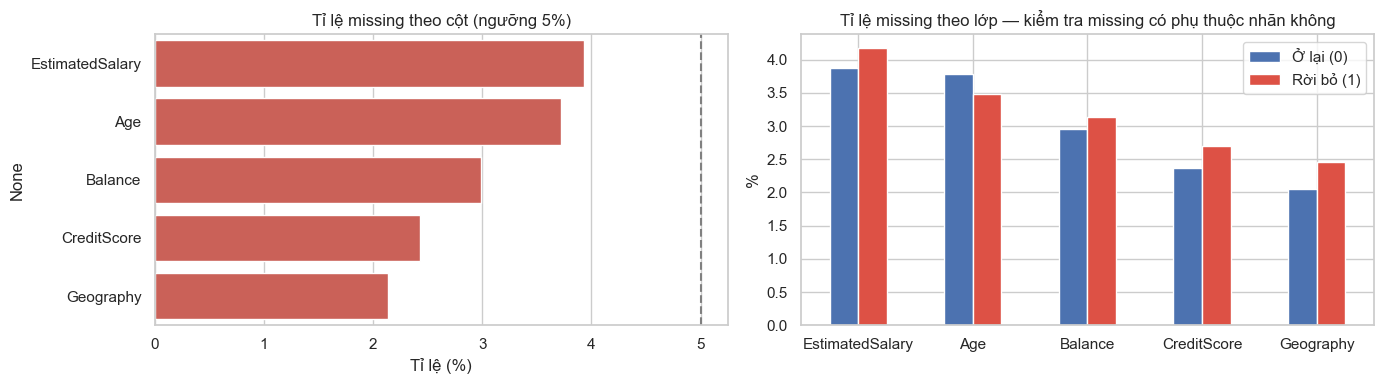

In [4]:
miss = df.isna().sum()
miss = pd.DataFrame({'Missing': miss, 'Tỉ lệ (%)': miss / len(df) * 100})
miss = miss[miss['Missing'] > 0].sort_values('Missing', ascending=False)
miss['Mức độ'] = pd.cut(miss['Tỉ lệ (%)'], [0, 5, 30, 100], labels=['Thấp', 'Trung bình', 'Cao'])
print(f'Tổng ô thiếu: {miss.Missing.sum():,} | số cột thiếu: {len(miss)} | dòng có ít nhất 1 ô thiếu: {df.isna().any(axis=1).mean():.1%}')
display(miss)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(x=miss['Tỉ lệ (%)'], y=miss.index, ax=axes[0], color='#DD5145')
axes[0].axvline(5, ls='--', c='gray'); axes[0].set_title('Tỉ lệ missing theo cột (ngưỡng 5%)')
rate_by_class = df[miss.index].isna().groupby(df[TARGET]).mean().T * 100
rate_by_class.columns = [CLASS_NAMES[c] for c in rate_by_class.columns]
rate_by_class.plot.bar(ax=axes[1], color=list(CLASS_COLORS.values()), rot=0)
axes[1].set(title='Tỉ lệ missing theo lớp — kiểm tra missing có phụ thuộc nhãn không', ylabel='%')
plt.tight_layout(); plt.show()

### 1.4. Phân phối các biến numerical

Hình dạng phân phối quyết định cách scaling. Nhóm so sánh mean với median và xem hệ số lệch (skewness);
quy ước thường dùng là |skew| lớn hơn 1 thì coi là lệch mạnh. Boxplot ở hàng dưới cho thấy outlier.

,mean,median,std,min,max,skew,% bằng 0
CreditScore,650.641,652.000,96.551,350.000,850.000,-0.070,0.000
Age,38.937,37.000,10.462,18.000,92.000,1.010,0.000
Tenure,5.013,5.000,2.892,0.000,10.000,0.011,4.130
Balance,"76,278.325","96,891.460","62,371.324",0.000,"250,898.090",-0.136,35.180
NumOfProducts,1.530,1.000,0.582,1.000,4.000,0.746,0.000
EstimatedSalary,"100,092.510","100,187.430","57,518.076",11.580,"199,992.480",0.002,0.000


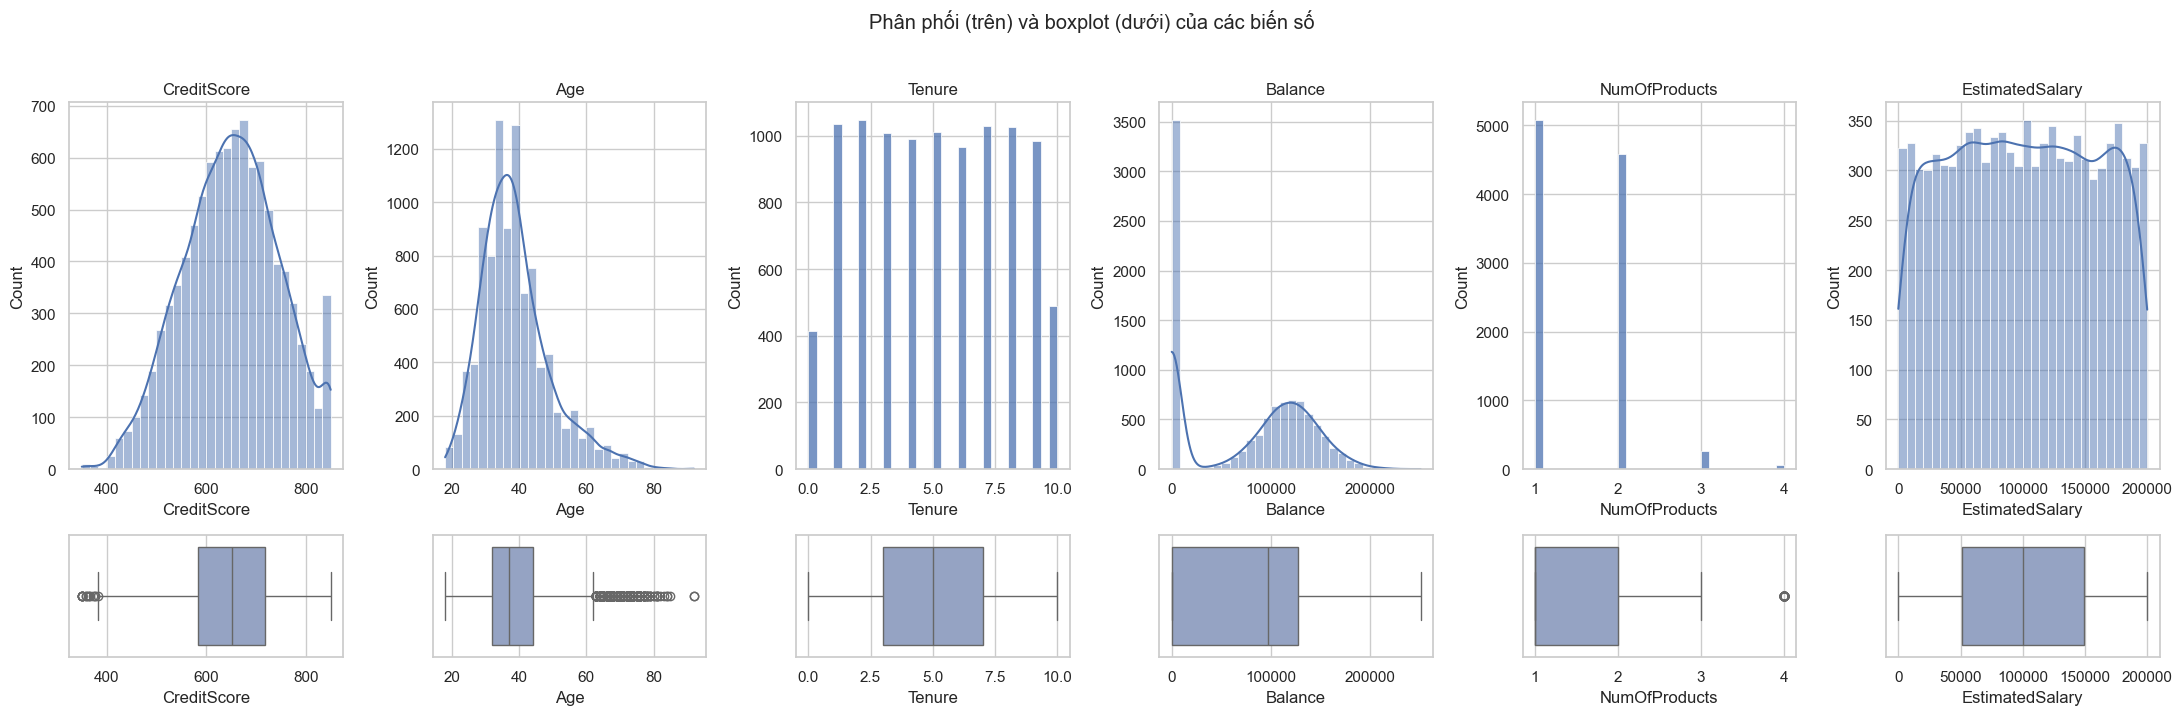

In [5]:
stats = df[NUM_COLS].describe().T[['mean', '50%', 'std', 'min', 'max']].rename(columns={'50%': 'median'})
stats['skew'] = df[NUM_COLS].skew()
stats['% bằng 0'] = (df[NUM_COLS] == 0).mean() * 100
display(stats)

fig, axes = plt.subplots(2, len(NUM_COLS), figsize=(22, 7), gridspec_kw={'height_ratios': [3, 1]})
for i, col in enumerate(NUM_COLS):
    sns.histplot(df[col].dropna(), bins=30, kde=col not in ['NumOfProducts', 'Tenure'], ax=axes[0, i], color='#4C72B0')
    axes[0, i].set_title(col)
    sns.boxplot(x=df[col], ax=axes[1, i], color='#8DA0CB')
plt.suptitle('Phân phối (trên) và boxplot (dưới) của các biến số', y=1.02)
plt.tight_layout(); plt.show()

### 1.5. Phân phối các biến categorical và binary

Số lượng giá trị khác nhau (cardinality) quyết định cách mã hóa: dưới 10 thì One-Hot, trên 50 nên dùng
Target hoặc Frequency Encoding. Nhóm nào chiếm dưới 1% thì nên gộp lại.

,Số giá trị,Mode,Tỉ lệ mode,Nhóm nhỏ nhất
Feature,,,,
Geography,3,France,0.503,0.247
Gender,2,Male,0.546,0.454
HasCrCard,2,1,0.706,0.294
IsActiveMember,2,1,0.515,0.485


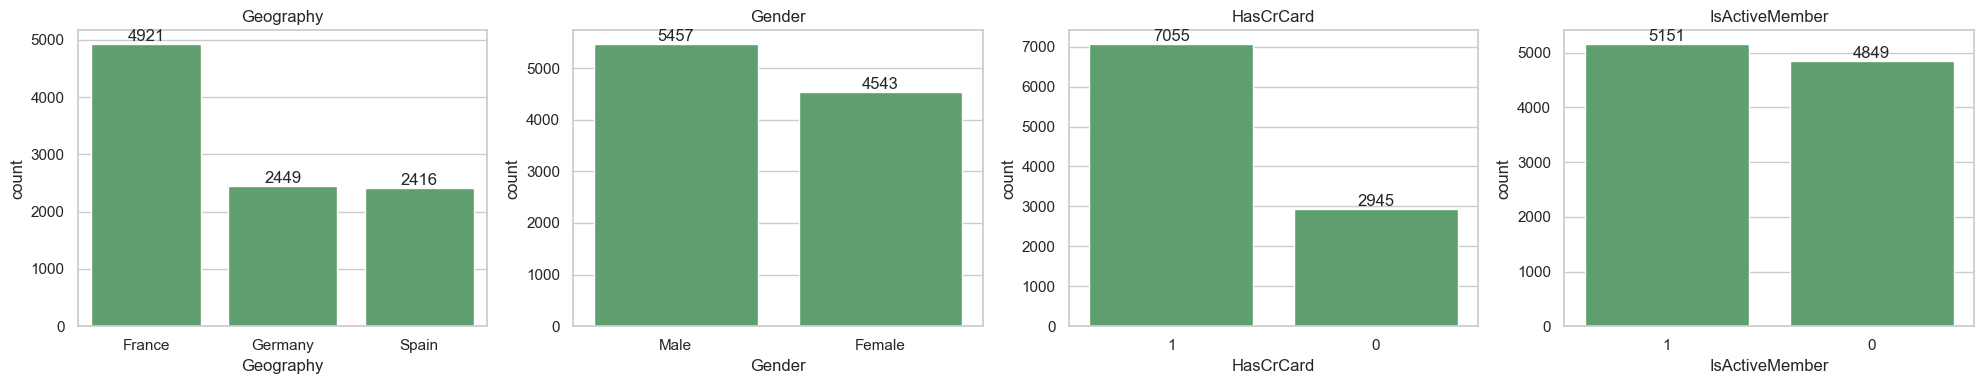

In [6]:
rows = []
for col in CAT_COLS + BIN_COLS:
    freq = df[col].value_counts(normalize=True)
    rows.append({
        'Feature': col,
        'Số giá trị': df[col].nunique(),
        'Mode': df[col].mode()[0],
        'Tỉ lệ mode': freq.iloc[0],
        'Nhóm nhỏ nhất': freq.iloc[-1],
    })
display(pd.DataFrame(rows).set_index('Feature'))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, CAT_COLS + BIN_COLS):
    sns.countplot(data=df, x=col, ax=ax, color='#55A868', order=df[col].value_counts().index)
    ax.bar_label(ax.containers[0], fmt='%d')
    ax.set_title(col)
plt.tight_layout(); plt.show()

### 1.6. Phân phối biến mục tiêu

Tỉ lệ hai lớp quyết định cách chia tập và cách chọn thước đo. Mức 40:60 đến 50:50 coi là cân bằng,
trên 2:1 là mất cân bằng, trên 10:1 là rất mất cân bằng. Nếu mất cân bằng thì cần chia tập phân tầng,
dùng class weight, và đánh giá bằng F1, Recall, PR-AUC thay vì Accuracy.

Ở lại: 7,963 (79.6%) | Rời bỏ: 2,037 (20.4%) | tỉ lệ 3.9:1
=> Một mô hình luôn đoán "Ở lại" đã đạt Accuracy 79.6% nhưng không bắt được khách hàng rời bỏ nào.


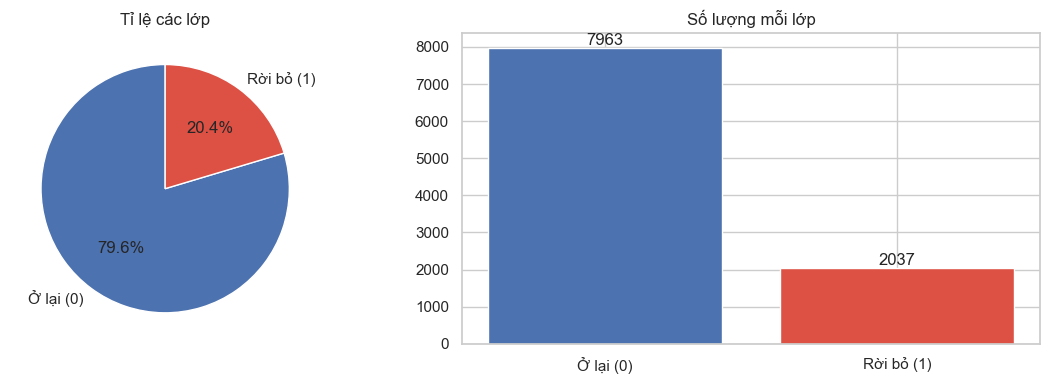

In [31]:
counts = df[TARGET].value_counts().sort_index()
print(f'Ở lại: {counts[0]:,} ({counts[0] / len(df):.1%}) | Rời bỏ: {counts[1]:,} ({counts[1] / len(df):.1%}) '
      f'| tỉ lệ {counts[0] / counts[1]:.1f}:1')
print(f'=> Một mô hình luôn đoán "Ở lại" đã đạt Accuracy {counts[0] / len(df):.1%} nhưng không bắt được khách hàng rời bỏ nào.')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].pie(counts, labels=[CLASS_NAMES[i] for i in counts.index], autopct='%1.1f%%',
            colors=list(CLASS_COLORS.values()), startangle=90)
axes[0].set_title('Tỉ lệ các lớp')
bars = axes[1].bar([CLASS_NAMES[i] for i in counts.index], counts, color=list(CLASS_COLORS.values()))
axes[1].bar_label(bars); axes[1].set_title('Số lượng mỗi lớp')
plt.tight_layout(); plt.show()

### 1.7. Phân tích tương quan

Nếu |r| lớn hơn 0.7 giữa hai feature thì có đa cộng tuyến, nên cân nhắc bỏ bớt một biến.
Nếu |r| nhỏ hơn 0.3 với biến mục tiêu thì quan hệ tuyến tính yếu, nhưng không có nghĩa là feature vô dụng:
quan hệ có thể phi tuyến mà hệ số Pearson không bắt được.

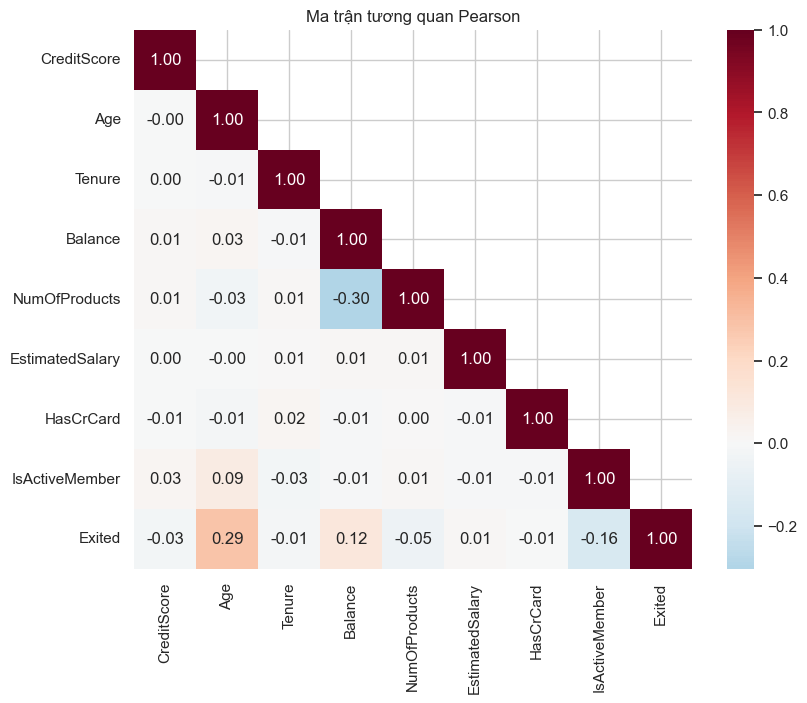

Cặp feature tương quan mạnh nhất: ('Balance', 'NumOfProducts') r = -0.30
Tương quan với Exited: {'Age': 0.29, 'IsActiveMember': -0.16, 'Balance': 0.12, 'NumOfProducts': -0.05, 'CreditScore': -0.03, 'EstimatedSalary': 0.01, 'Tenure': -0.01, 'HasCrCard': -0.01}


In [8]:
corr = df[NUM_COLS + BIN_COLS + [TARGET]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, mask=np.triu(np.ones_like(corr, dtype=bool), 1))
plt.title('Ma trận tương quan Pearson'); plt.show()

pairs = corr.drop(index=TARGET, columns=TARGET).where(np.triu(np.ones((len(corr) - 1,) * 2, dtype=bool), 1)).stack()
print(f'Cặp feature tương quan mạnh nhất: {pairs.abs().idxmax()} r = {pairs[pairs.abs().idxmax()]:.2f}')
print('Tương quan với Exited:', corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(2).to_dict())

### 1.8. Phát hiện outlier bằng IQR

Giá trị nằm ngoài khoảng $[Q_1 - 1{,}5\,IQR,\; Q_3 + 1{,}5\,IQR]$ được coi là outlier.
Mức độ: dưới 1% là thấp, 1–5% là trung bình, trên 5% là cao.
Bảng nhóm tuổi bên dưới dùng để quyết định nên giữ hay loại các giá trị này.

In [30]:
def iqr_table(data, cols, k=1.5):
    rows = []
    for c in cols:
        s = data[c].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        lo, hi = q1 - k * (q3 - q1), q3 + k * (q3 - q1)
        n = ((s < lo) | (s > hi)).sum()
        rows.append({'Feature': c, 'Outliers': n, 'Tỉ lệ (%)': n / len(s) * 100,
                     'Khoảng hợp lệ': f'[{lo:,.1f}, {hi:,.1f}]'})
    t = pd.DataFrame(rows).set_index('Feature')
    t['Mức độ'] = pd.cut(t['Tỉ lệ (%)'], [-0.01, 1, 5, 100], labels=['Thấp', 'Trung bình', 'Cao'])
    return t


outliers = iqr_table(df, NUM_COLS)
display(outliers)

age_groups = df.groupby(pd.cut(df['Age'], [17, 30, 40, 50, 62, 70, 100]), observed=True)[TARGET]
age_table = age_groups.agg(['size', 'mean']).rename(columns={'size': 'Số KH', 'mean': '% rời bỏ'})
display(age_table.rename_axis('Nhóm tuổi'))

print(f"Tỉ lệ rời bỏ nhóm 50-62 tuổi : {age_table.loc[pd.Interval(50, 62), '% rời bỏ']:.1%}")
print(f"Tỉ lệ rời bỏ nhóm 62-70 tuổi : {age_table.loc[pd.Interval(62, 70), '% rời bỏ']:.1%}")
print(f"Tỉ lệ rời bỏ nhóm > 70 tuổi  : {age_table.loc[pd.Interval(70, 100), '% rời bỏ']:.1%}")
print('=> Tỉ lệ rời bỏ tăng tới khoảng 60 tuổi rồi giảm lại. Cắt bỏ outlier sẽ mất đoạn giảm này.')

,Outliers,Tỉ lệ (%),Khoảng hợp lệ,Mức độ
Feature,,,,
CreditScore,15,0.154,"[383.0, 919.0]",Thấp
Age,348,3.614,"[14.0, 62.0]",Trung bình
Tenure,0,0.000,"[-3.0, 13.0]",Thấp
Balance,0,0.000,"[-191,318.3, 318,863.9]",Thấp
NumOfProducts,60,0.600,"[-0.5, 3.5]",Thấp
EstimatedSalary,0,0.000,"[-96,099.5, 296,760.7]",Thấp


,Số KH,% rời bỏ
Nhóm tuổi,,
"(17, 30]",1878,0.075
"(30, 40]",4305,0.122
"(40, 50]",2229,0.339
"(50, 62]",868,0.547
"(62, 70]",222,0.270
"(70, 100]",126,0.087


Tỉ lệ rời bỏ nhóm 50-62 tuổi : 54.7%
Tỉ lệ rời bỏ nhóm 62-70 tuổi : 27.0%
Tỉ lệ rời bỏ nhóm > 70 tuổi  : 8.7%
=> Tỉ lệ rời bỏ tăng tới khoảng 60 tuổi rồi giảm lại. Cắt bỏ outlier sẽ mất đoạn giảm này.


### 1.9. Quan hệ giữa biến mục tiêu và các feature

Với biến categorical, nhóm so sánh tỉ lệ rời bỏ của từng nhóm với tỉ lệ chung.
Với biến numerical, so sánh phân phối của hai lớp. Chênh lệch càng lớn thì feature càng có khả năng dự báo.

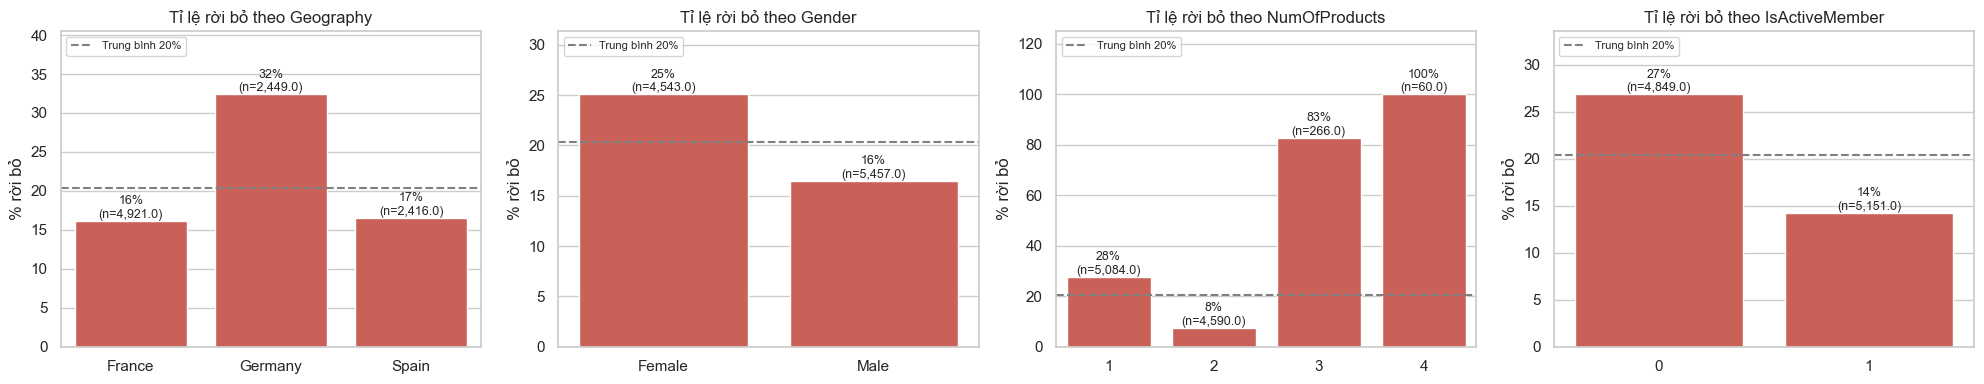

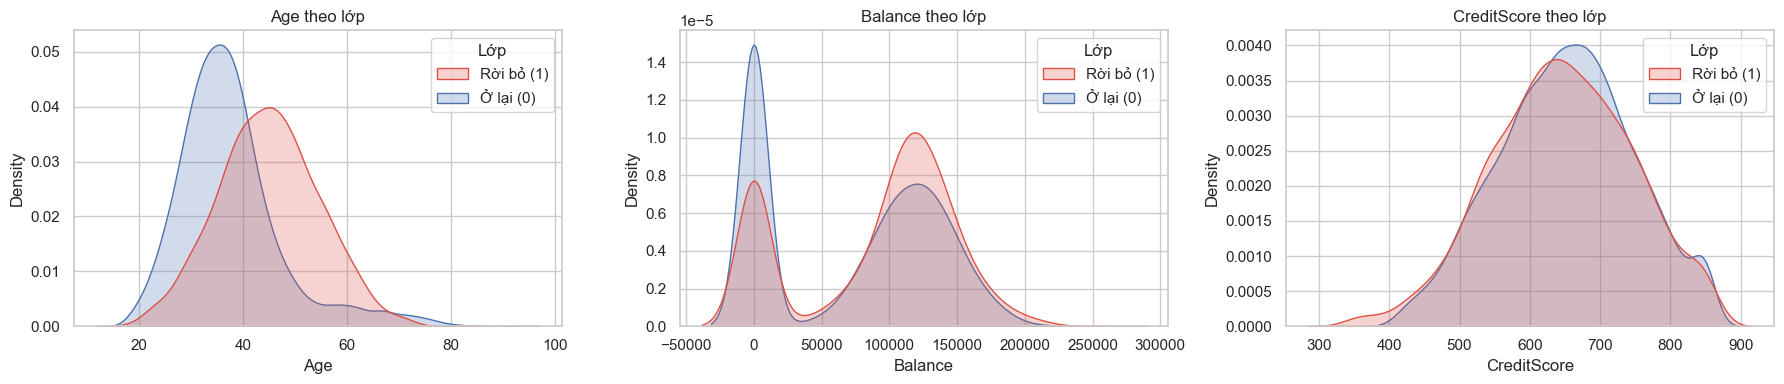

Exited,Ở lại (0),Rời bỏ (1)
Median,,
CreditScore,653.000,646.000
Age,36.000,45.000
Tenure,5.000,5.000
Balance,"91,561.785","109,052.590"
NumOfProducts,2.000,1.000
EstimatedSalary,"99,654.130","102,431.875"


In [10]:
overall = df[TARGET].mean()
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, ['Geography', 'Gender', 'NumOfProducts', 'IsActiveMember']):
    rate = df.groupby(col)[TARGET].agg(['mean', 'size'])
    sns.barplot(x=rate.index.astype(str), y=rate['mean'] * 100, ax=ax, color='#DD5145')
    ax.bar_label(ax.containers[0], labels=[f'{m:.0%}\n(n={n:,})' for m, n in rate.values], fontsize=9)
    ax.axhline(overall * 100, ls='--', c='gray', label=f'Trung bình {overall:.0%}')
    ax.set(title=f'Tỉ lệ rời bỏ theo {col}', ylabel='% rời bỏ', xlabel='', ylim=(0, rate['mean'].max() * 125))
    ax.legend(loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ['Age', 'Balance', 'CreditScore']):
    sns.kdeplot(data=df.assign(Lớp=df[TARGET].map(CLASS_NAMES)), x=col, hue='Lớp', common_norm=False, fill=True,
                palette={CLASS_NAMES[k]: v for k, v in CLASS_COLORS.items()}, ax=ax)
    ax.set_title(f'{col} theo lớp')
plt.tight_layout(); plt.show()
display(df.groupby(TARGET)[NUM_COLS].median().rename(index=CLASS_NAMES).T.rename_axis('Median'))

### 1.10. Những điều rút ra từ EDA

**Chất lượng dữ liệu.** Bộ dữ liệu có 10.000 khách hàng và 14 cột, không có dòng trùng lặp hay CustomerId trùng.
Sau khi loại 3 cột định danh còn 10 feature: 6 numerical, 2 binary, 2 categorical.
Có 1.521 ô thiếu nằm ở 5 cột, mỗi cột 2,1–3,9% nên đều ở mức thấp. Tuy nhiên, vì các cột thiếu độc lập nhau
nên có tới **14,1% số dòng** chứa ít nhất một ô thiếu. Xóa dòng sẽ mất 14% dữ liệu, vì vậy nhóm chọn điền
median cho biến số và mode cho biến phân loại. Tỉ lệ thiếu ở hai lớp gần như bằng nhau (Age: 3,8% so với 3,5%),
đúng với cơ chế MCAR mà nhóm đã tạo ra.

**Phân phối.** Age lệch phải với skew = 1,01, median 37 tuổi còn giá trị lớn nhất là 92.
Balance có hai đỉnh rõ rệt vì **35,2% khách hàng có số dư bằng 0**, khiến mean (76 nghìn) thấp hơn hẳn
median của nhóm có số dư (97 nghìn). Đây là lý do nhóm tách riêng đặc trưng `IsZeroBalance`.
CreditScore và EstimatedSalary gần như đối xứng (|skew| dưới 0,1), riêng EstimatedSalary gần với phân phối đều,
tức là nó có vẻ được sinh ngẫu nhiên chứ không mang nhiều thông tin. Các biến categorical đều có không quá
3 giá trị nên dùng One-Hot là phù hợp.

**Biến mục tiêu và tương quan.** Tỉ lệ hai lớp là 3,9:1 (79,6% ở lại, 20,4% rời bỏ). Điều này có hệ quả trực tiếp:
một mô hình luôn đoán "ở lại" đã đạt Accuracy 79,6% mà không bắt được khách hàng nào, nên Accuracy không dùng được
làm thước đo chính. Không có dấu hiệu đa cộng tuyến, cặp tương quan mạnh nhất chỉ là Balance với NumOfProducts
(r = −0,30). Tương quan tuyến tính với Exited đều yếu: Age 0,29, IsActiveMember −0,16, Balance 0,12.
Riêng NumOfProducts chỉ đạt −0,05, nhưng phần 1.9 cho thấy nó lại là feature mạnh nhất, nên hệ số Pearson
ở đây gây hiểu nhầm. Đó là một lý do nữa để ưu tiên mô hình phi tuyến. Về outlier, chủ yếu nằm ở Age
(348 khách hàng trên 62 tuổi, chiếm 3,6%) và NumOfProducts (60 khách hàng dùng 4 sản phẩm, 0,6%).

**Yếu tố phân biệt rõ nhất.** NumOfProducts có quan hệ hoàn toàn phi tuyến: dùng 1 sản phẩm thì 27,7% rời bỏ,
2 sản phẩm chỉ 7,6%, 3 sản phẩm vọt lên 82,7%, còn 4 sản phẩm là 100%. Con số 100% nghe rất mạnh nhưng chỉ dựa trên
60 khách hàng, nên nhóm không coi đó là quy luật chắc chắn mà chỉ xem nhóm từ 3 sản phẩm trở lên là nhóm rủi ro cao.
Về tuổi, median của nhóm rời bỏ là 45 so với 36 ở nhóm ở lại; tỉ lệ rời bỏ tăng từ 7,5% ở nhóm dưới 30 tuổi
lên 54,7% ở nhóm 50–62 tuổi rồi giảm còn 8,7% ở nhóm trên 70. Ngoài ra khách hàng Đức rời bỏ nhiều gấp đôi
(32,4% so với 16,1% ở Pháp và 16,6% ở Tây Ban Nha), nữ nhiều hơn nam (25,1% so với 16,5%),
và người không hoạt động nhiều hơn người hoạt động (26,9% so với 14,3%).

## 2. Chuẩn bị dữ liệu

Nguyên tắc xuyên suốt phần này: mọi bước có học tham số từ dữ liệu, gồm median để điền thiếu, IQR để scale
và danh sách giá trị để one-hot, đều phải nằm trong `Pipeline` và chỉ được `fit` trên tập Train.
Nếu fit trên toàn bộ dữ liệu thì thông tin của Validation và Test sẽ rò rỉ sang Train, và kết quả đánh giá
sẽ lạc quan hơn thực tế.

### 2.1. Loại cột định danh và kiểm tra trùng lặp

In [11]:
data = df.drop(columns=ID_COLS)
print(f'Sau khi bỏ {ID_COLS}: {data.shape[1]} cột | dòng trùng lặp: {data.duplicated().sum()}')

Sau khi bỏ ['RowNumber', 'CustomerId', 'Surname']: 11 cột | dòng trùng lặp: 0


### 2.2. Tạo đặc trưng từ kết quả EDA

Nhóm thêm hai đặc trưng, cả hai đều xuất phát từ những gì quan sát được ở phần 1.

`IsZeroBalance` bằng 1 khi `Balance` bằng 0. Lý do là Balance có phân phối hai đỉnh với 35,2% khách hàng
số dư bằng 0, và hai nhóm này có tỉ lệ rời bỏ khác hẳn nhau. Mô hình tuyến tính không tự tách được một đỉnh
như vậy nếu chỉ nhìn giá trị thô.

`ProductsGroup` là `NumOfProducts` chuyển sang dạng categorical, gộp giá trị 3 và 4 thành nhóm `3+`.
Lý do gộp: quan hệ với tỉ lệ rời bỏ không hề tuyến tính (2 sản phẩm thấp nhất, từ 3 trở lên rất cao),
nên để dạng số sẽ buộc mô hình tuyến tính hiểu sai; còn nhóm 4 sản phẩm chỉ có 60 khách hàng nên theo quy tắc
nhóm hiếm thì nên gộp.

Hai phép biến đổi này chỉ tính trên từng dòng, không học tham số gì từ dữ liệu, nên đặt chúng trong
`FunctionTransformer` ở đầu pipeline là an toàn và giúp hàm suy luận ở phần 4 nhận được dữ liệu thô.

In [ ]:
def add_features(X):
    X = X.copy()

    X['IsZeroBalance'] = np.where(X['Balance'].isna(), np.nan, (X['Balance'] == 0).astype(float))

    products = pd.to_numeric(X['NumOfProducts'], errors='coerce').clip(upper=3)
    X['ProductsGroup'] = products.map({1.0: '1', 2.0: '2', 3.0: '3+'})

    return X.drop(columns=['NumOfProducts'])


feature_maker = FunctionTransformer(add_features)
display(add_features(data.drop(columns=TARGET)).head())

churn_by_zero = data.groupby(add_features(data)['IsZeroBalance'])[TARGET].mean()
print(f"Tỉ lệ rời bỏ khi Balance = 0 : {churn_by_zero[1.0]:.1%}")
print(f"Tỉ lệ rời bỏ khi Balance > 0 : {churn_by_zero[0.0]:.1%}")

check = pd.DataFrame([{'Balance': np.nan, 'NumOfProducts': np.nan}])
print('\nThử với Balance và NumOfProducts đều thiếu:')
print(add_features(check).to_dict('records')[0])

,CreditScore,Geography,Gender,Age,Tenure,Balance,HasCrCard,IsActiveMember,EstimatedSalary,IsZeroBalance,ProductsGroup
0,619.000,France,Female,42.000,2,0.000,1,1,"101,348.880",1.000,1
1,608.000,Spain,Female,41.000,1,"83,807.860",0,1,"112,542.580",0.000,1
2,502.000,France,Female,42.000,8,"159,660.800",1,0,"113,931.570",0.000,3+
3,699.000,France,Female,39.000,1,0.000,0,0,NaN,1.000,2
4,850.000,Spain,Female,43.000,2,"125,510.820",1,1,"79,084.100",0.000,1


Tỉ lệ rời bỏ khi Balance = 0 : 13.8%
Tỉ lệ rời bỏ khi Balance > 0 : 24.0%

Thử với Balance và NumOfProducts đều thiếu:
{'Balance': nan, 'IsZeroBalance': nan, 'ProductsGroup': nan}


### 2.3. Chia tập Train, Validation và Test theo tỉ lệ 70/15/15

Train dùng để huấn luyện, Validation để so sánh mô hình và chọn ngưỡng, còn Test chỉ được đụng tới
đúng một lần ở phần 4. Tham số `stratify=y` giữ tỉ lệ rời bỏ khoảng 20% ở cả ba tập, tránh trường hợp
một tập tình cờ có quá ít khách hàng rời bỏ. Việc chia được làm trước khi điền thiếu và scale.

In [15]:
X, y = data.drop(columns=TARGET), data[TARGET]
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE)

display(pd.DataFrame({name: {'Số mẫu': len(t), 'Tỉ lệ': len(t) / len(X), 'Số rời bỏ': int(t.sum()), '% rời bỏ': t.mean()}
                      for name, t in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]}).T)

,Số mẫu,Tỉ lệ,Số rời bỏ,% rời bỏ
Train,"7,000.000",0.700,"1,426.000",0.204
Validation,"1,500.000",0.150,306.000,0.204
Test,"1,500.000",0.150,305.000,0.203


### 2.4. Pipeline tiền xử lý

| Nhóm cột | Điền thiếu | Scaling | Encoding |
|---|---|---|---|
| Numerical: CreditScore, Age, Tenure, Balance, EstimatedSalary | median | RobustScaler | — |
| Binary: HasCrCard, IsActiveMember, IsZeroBalance | mode | giữ nguyên 0/1 | — |
| Categorical: Geography, Gender, ProductsGroup | mode | — | One-Hot |

Về outlier: nhóm quyết định **giữ lại**. Các giá trị Age từ 63 đến 92 là tuổi thật, không phải lỗi nhập liệu.
Quan trọng hơn, bảng nhóm tuổi ở phần 1.8 cho thấy tỉ lệ rời bỏ tăng tới nhóm 50–62 tuổi (54,7%) rồi
giảm mạnh ở nhóm trên 70 (8,7%). Nếu cắt bỏ phần đuôi này thì mô hình sẽ mất hẳn đoạn giảm đó và có thể
ngoại suy sai rằng càng già càng dễ rời bỏ. Thay vì xóa, nhóm dùng RobustScaler vì nó chuẩn hóa theo median
và IQR nên ít bị đuôi phân phối kéo lệch; các mô hình cây thì vốn không nhạy với outlier.

In [16]:
NUM_FEATURES = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary']
BIN_FEATURES = ['HasCrCard', 'IsActiveMember', 'IsZeroBalance']
CAT_FEATURES = ['Geography', 'Gender', 'ProductsGroup']


def build_preprocessor():
    columns = ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', RobustScaler())]), NUM_FEATURES),
        ('bin', SimpleImputer(strategy='most_frequent'), BIN_FEATURES),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CAT_FEATURES),
    ], verbose_feature_names_out=False)
    return Pipeline([('features', FunctionTransformer(add_features)), ('columns', columns)])


prep = build_preprocessor().fit(X_train)
Xt_train = pd.DataFrame(prep.transform(X_train), columns=prep.named_steps['columns'].get_feature_names_out(),
                        index=X_train.index)
print(f'Sau tiền xử lý: {Xt_train.shape[1]} cột | missing còn lại: {int(Xt_train.isna().sum().sum())}')
print('Median dùng để điền (học từ Train):',
      {c: float(v) for c, v in zip(NUM_FEATURES, prep.named_steps['columns'].named_transformers_['num']['imputer'].statistics_.round(1))})
Xt_train.head()

Sau tiền xử lý: 16 cột | missing còn lại: 0
Median dùng để điền (học từ Train): {'CreditScore': 652.0, 'Age': 37.0, 'Tenure': 5.0, 'Balance': 96479.8, 'EstimatedSalary': 98511.7}


,CreditScore,Age,Tenure,Balance,EstimatedSalary,HasCrCard,IsActiveMember,IsZeroBalance,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male,ProductsGroup_1,ProductsGroup_2,ProductsGroup_3+
9136,-0.438,-1.545,-0.200,-0.005,0.842,1.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,1.000,0.000,0.000
6410,0.000,2.364,-0.800,-0.762,0.936,1.000,1.000,1.000,0.000,0.000,1.000,1.000,0.000,0.000,1.000,0.000
2607,1.246,-0.545,-0.800,0.177,0.034,1.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,1.000,0.000,0.000
3201,0.538,-1.545,0.200,-0.762,1.031,1.000,0.000,1.000,1.000,0.000,0.000,0.000,1.000,0.000,1.000,0.000
3330,0.662,-1.727,-0.200,-0.762,-0.539,1.000,1.000,1.000,1.000,0.000,0.000,0.000,1.000,0.000,1.000,0.000


### 2.5. Kiểm tra bằng hình: trước và sau khi điền thiếu và scale

So sánh phân phối gốc với hai cách scale, trên hai biến có vấn đề là `Age` (lệch phải, nhiều outlier)
và `Balance` (hai đỉnh).

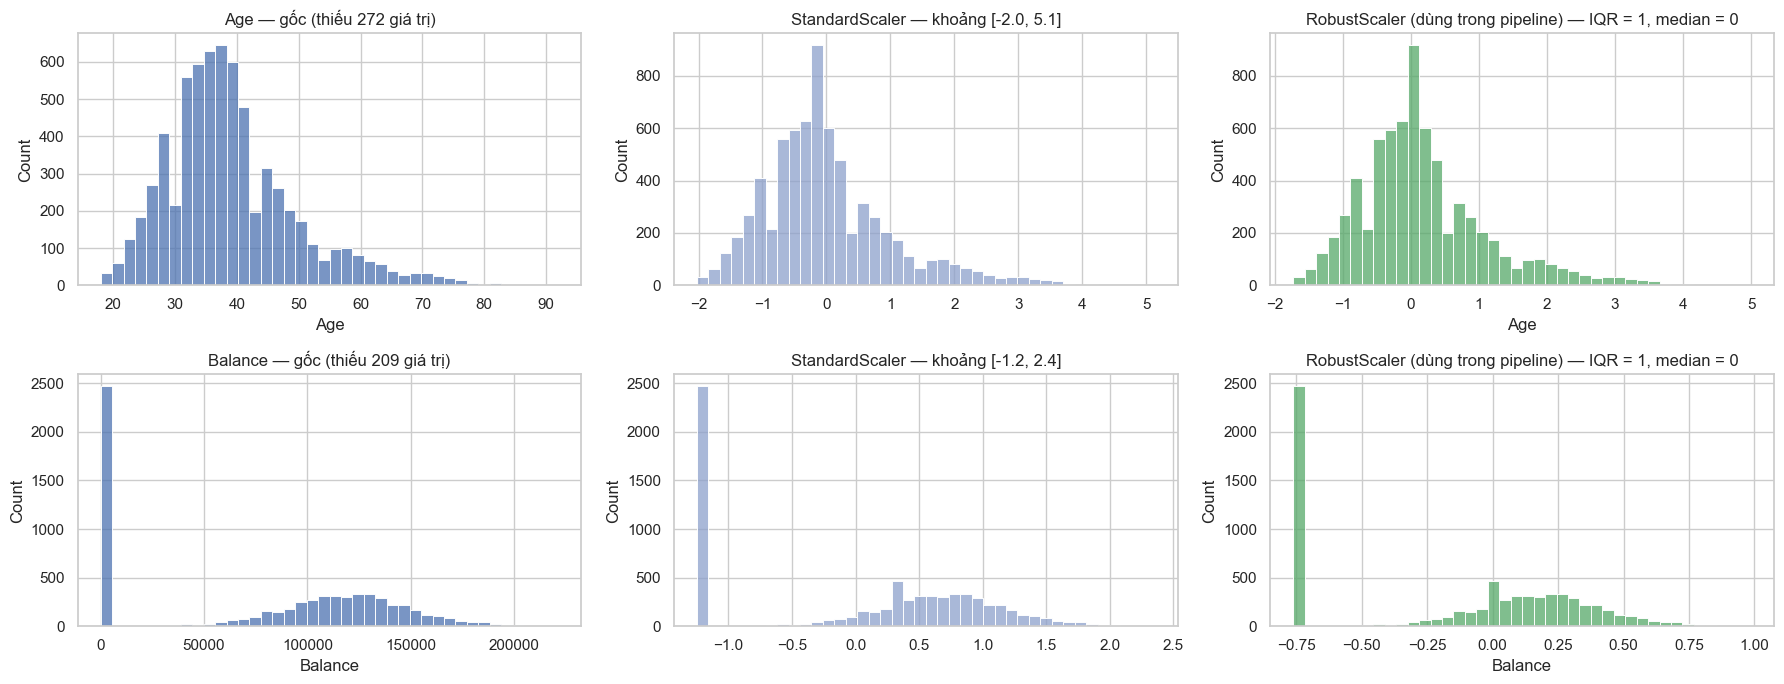

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for r, col in enumerate(['Age', 'Balance']):
    raw = X_train[col]
    filled = raw.fillna(raw.median())
    std_scaled = StandardScaler().fit_transform(filled.to_frame()).ravel()
    sns.histplot(raw.dropna(), bins=40, ax=axes[r, 0], color='#4C72B0')
    axes[r, 0].set_title(f'{col} — gốc (thiếu {raw.isna().sum()} giá trị)')
    sns.histplot(std_scaled, bins=40, ax=axes[r, 1], color='#8DA0CB')
    axes[r, 1].set_title(f'StandardScaler — khoảng [{std_scaled.min():.1f}, {std_scaled.max():.1f}]')
    sns.histplot(Xt_train[col], bins=40, ax=axes[r, 2], color='#55A868')
    axes[r, 2].set_title(f'RobustScaler (dùng trong pipeline) — IQR = 1, median = 0')
plt.tight_layout(); plt.show()

Vài điều xác nhận lại sau phần 2:

`IsZeroBalance` quả thật tách được hai nhóm khác nhau: khách hàng có số dư bằng 0 rời bỏ 13,8%,
còn khách hàng có số dư rời bỏ 24,0%. Chênh lệch gần gấp đôi, đủ để giữ đặc trưng này.

Sau khi chia phân tầng, tỉ lệ rời bỏ ở Train, Validation và Test lần lượt là 20,4%, 20,4% và 20,3%,
tức ba tập đồng nhất về mặt nhãn.

Pipeline biến 10 cột gốc thành 16 cột số và không còn ô thiếu nào. Các giá trị median dùng để điền
chỉ học từ Train, ví dụ Age là 37.

Hình trên cho thấy khác biệt giữa hai scaler: StandardScaler bị các giá trị Age lớn kéo dài đuôi phải,
còn RobustScaler giữ phần thân phân phối quanh 0 với IQR bằng 1. Khác biệt không quá lớn ở bộ này,
nhưng RobustScaler là lựa chọn an toàn hơn.

## 3. Phân tích và mô hình hóa

### 3.1. Thước đo đánh giá

Vì dữ liệu mất cân bằng, Accuracy dễ gây hiểu nhầm nên nhóm dùng bốn thước đo khác.
F1 của lớp rời bỏ là thước đo chính vì nó cân bằng giữa Precision và Recall.
Recall cho biết bắt được bao nhiêu phần trăm khách hàng sắp rời đi; trong bài toán giữ chân khách hàng,
bỏ sót một người sắp rời bỏ thường tốn kém hơn gọi nhầm một người vẫn đang ở lại.
ROC-AUC và PR-AUC đánh giá khả năng xếp hạng của mô hình mà không phụ thuộc vào ngưỡng, nên dùng để
so sánh các thuật toán một cách công bằng.

### 3.2. Baseline và so sánh các mô hình trên Validation

Nhóm dùng hai baseline. Baseline thứ nhất là `DummyClassifier` luôn đoán lớp đa số, để biết mức Accuracy
"miễn phí" là bao nhiêu. Baseline thứ hai là Logistic Regression không xử lý mất cân bằng, đại diện cho
cách làm đơn giản nhất mà vẫn là mô hình thật.

Ba thuật toán được so sánh là Logistic Regression, Random Forest và HistGradientBoosting. Mỗi thuật toán
chạy hai phiên bản: để mặc định và đặt `class_weight='balanced'`, tức là phạt lỗi trên lớp thiểu số nặng hơn
theo tỉ lệ nghịch với tần suất lớp.

In [20]:
def evaluate(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {'Accuracy': accuracy_score(y_true, pred), 'Precision': precision_score(y_true, pred, zero_division=0),
            'Recall': recall_score(y_true, pred), 'F1': f1_score(y_true, pred),
            'ROC-AUC': roc_auc_score(y_true, prob), 'PR-AUC': average_precision_score(y_true, prob)}


def make_pipeline(clf):
    return Pipeline([('prep', build_preprocessor()), ('clf', clf)])


ALGORITHMS = {
    'LogisticRegression': lambda cw: LogisticRegression(max_iter=2000, class_weight=cw),
    'RandomForest': lambda cw: RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight=cw,
                                                      n_jobs=-1, random_state=RANDOM_STATE),
    'HistGradientBoosting': lambda cw: HistGradientBoostingClassifier(class_weight=cw, random_state=RANDOM_STATE),
}

models = {'Dummy (lớp đa số)': make_pipeline(DummyClassifier(strategy='most_frequent'))}
for name, factory in ALGORITHMS.items():
    models[name] = make_pipeline(factory(None))
    models[f'{name} + balanced'] = make_pipeline(factory('balanced'))

val_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    val_rows.append({'Mô hình': name, **evaluate(y_val, model.predict_proba(X_val)[:, 1])})
val_results = pd.DataFrame(val_rows).set_index('Mô hình')
display(val_results.style.format('{:.3f}').highlight_max(color='#c6efce', axis=0))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Mô hình,,,,,,
Dummy (lớp đa số),0.796,0.000,0.000,0.000,0.500,0.204
LogisticRegression,0.844,0.740,0.363,0.487,0.854,0.662
LogisticRegression + balanced,0.770,0.463,0.788,0.583,0.857,0.660
RandomForest,0.873,0.807,0.493,0.613,0.881,0.724
RandomForest + balanced,0.852,0.634,0.650,0.642,0.879,0.720
HistGradientBoosting,0.864,0.766,0.480,0.590,0.884,0.724
HistGradientBoosting + balanced,0.828,0.561,0.719,0.630,0.876,0.718


Câu hỏi đặt ra: đặt `class_weight='balanced'` làm Recall và F1 của từng thuật toán thay đổi thế nào?

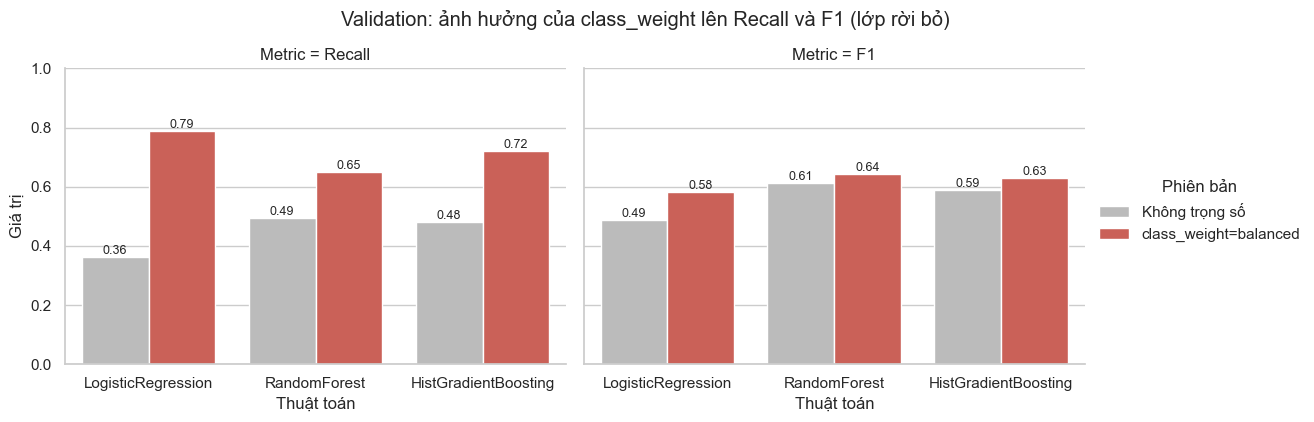

In [21]:
plot_rows = []
for name in ALGORITHMS:
    for suffix, label in [('', 'Không trọng số'), (' + balanced', 'class_weight=balanced')]:
        r = val_results.loc[name + suffix]
        plot_rows += [{'Thuật toán': name, 'Phiên bản': label, 'Metric': m, 'Giá trị': r[m]} for m in ['Recall', 'F1']]
plot_df = pd.DataFrame(plot_rows)

g = sns.catplot(data=plot_df, x='Thuật toán', y='Giá trị', hue='Phiên bản', col='Metric', kind='bar',
                palette=['#BBBBBB', '#DD5145'], height=4, aspect=1.4)
for ax in g.axes.flat:
    for c in ax.containers:
        ax.bar_label(c, fmt='%.2f', fontsize=9)
    ax.set_ylim(0, 1)
g.figure.suptitle('Validation: ảnh hưởng của class_weight lên Recall và F1 (lớp rời bỏ)', y=1.05)
plt.show()

Kết quả trên Validation cho thấy mấy điều.

Accuracy đúng là gây hiểu nhầm như dự đoán: Dummy đạt Accuracy 0,796 nhưng F1 bằng 0 vì không bắt được
khách hàng rời bỏ nào. Logistic Regression thường còn có Accuracy cao hơn (0,844) nhưng chỉ bắt được
36% số khách hàng rời bỏ.

`class_weight='balanced'` làm Recall tăng mạnh ở cả ba thuật toán: Logistic Regression từ 0,36 lên 0,79,
Random Forest từ 0,49 lên 0,65, HistGradientBoosting từ 0,48 lên 0,72. F1 cũng tăng theo
(0,487 lên 0,583; 0,613 lên 0,642; 0,590 lên 0,630), đổi lại Precision giảm, rõ nhất ở
Logistic Regression khi tụt từ 0,74 xuống 0,46.

Điều đáng chú ý là ROC-AUC gần như không đổi khi thêm trọng số, ví dụ Random Forest là 0,881 so với 0,879.
Nghĩa là class weight không làm mô hình phân biệt hai lớp tốt hơn, nó chỉ dịch ranh giới quyết định
về phía lớp thiểu số. Đây là điểm nhóm thấy dễ bị hiểu nhầm nhất: nhìn Recall tăng từ 0,36 lên 0,79
dễ tưởng mô hình "giỏi hơn hẳn", trong khi thực chất nó chỉ đang dự đoán "rời bỏ" nhiều hơn.

Cuối cùng, hai mô hình cây vượt Logistic Regression (ROC-AUC khoảng 0,88 so với 0,85; PR-AUC 0,72 so với 0,66).
Điều này khớp với EDA, vì quan hệ giữa Age, NumOfProducts và Exited đều phi tuyến.

### 3.3. Tinh chỉnh siêu tham số bằng GridSearchCV

Nhóm chỉ tinh chỉnh hai mô hình cây vì chúng tốt hơn rõ rệt ở bước trước. Dùng 5-fold phân tầng trên Train,
tiêu chí chọn là F1. `class_weight` được đưa vào lưới tìm kiếm như một siêu tham số bình thường,
để xem cross-validation có tự chọn `balanced` hay không thay vì nhóm áp đặt.

In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
GRIDS = {
    'RandomForest': (ALGORITHMS['RandomForest'](None),
                     {'clf__max_depth': [8, 12, None], 'clf__min_samples_leaf': [2, 5, 10],
                      'clf__class_weight': [None, 'balanced']}),
    'HistGradientBoosting': (ALGORITHMS['HistGradientBoosting'](None),
                             {'clf__learning_rate': [0.05, 0.1], 'clf__max_leaf_nodes': [15, 31],
                              'clf__max_iter': [100, 300], 'clf__class_weight': [None, 'balanced']}),
}

tuned, tune_rows = {}, []
for name, (clf, grid) in GRIDS.items():
    search = GridSearchCV(make_pipeline(clf), grid, scoring='f1', cv=cv, n_jobs=-1).fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    prob = tuned[name].predict_proba(X_val)[:, 1]
    tune_rows.append({'Mô hình': f'{name} (tuned)', 'CV F1': search.best_score_, **evaluate(y_val, prob),
                      'Tham số tốt nhất': {k.replace('clf__', ''): v for k, v in search.best_params_.items()}})
tune_results = pd.DataFrame(tune_rows).set_index('Mô hình')
display(tune_results.drop(columns='Tham số tốt nhất'))
for name, params in tune_results['Tham số tốt nhất'].items():
    print(f'{name}: {params}')

,CV F1,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Mô hình,,,,,,,
RandomForest (tuned),0.599,0.831,0.569,0.716,0.634,0.879,0.718
HistGradientBoosting (tuned),0.596,0.828,0.561,0.719,0.630,0.876,0.718


RandomForest (tuned): {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 10}
HistGradientBoosting (tuned): {'class_weight': 'balanced', 'learning_rate': 0.1, 'max_iter': 100, 'max_leaf_nodes': 31}


### 3.4. Chọn ngưỡng quyết định trên Validation

Mặc định `predict` coi một khách hàng là rời bỏ khi xác suất từ 0,5 trở lên. Với dữ liệu mất cân bằng,
ngưỡng này hiếm khi là lựa chọn tốt nhất cho F1. Nhóm quét các ngưỡng từ 0,10 đến 0,90 trên Validation
và chọn ngưỡng cho F1 cao nhất. Tập Test không tham gia bước này.

Mô hình cuối: RandomForest | ngưỡng tối ưu trên Validation = 0.61


,Precision,Recall,F1
threshold,,,
ngưỡng 0.50,0.569,0.716,0.634
ngưỡng 0.61,0.693,0.605,0.646


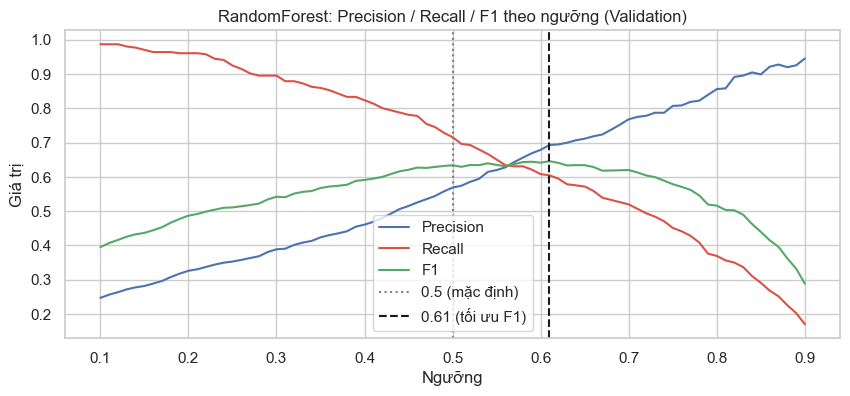

In [23]:
THRESHOLDS = np.round(np.arange(0.10, 0.91, 0.01), 2)
best_name = tune_results['F1'].idxmax().replace(' (tuned)', '')
final_model = tuned[best_name]
val_prob = final_model.predict_proba(X_val)[:, 1]

curve = pd.DataFrame([{'threshold': t, **evaluate(y_val, val_prob, t)} for t in THRESHOLDS]).set_index('threshold')
best_threshold = float(curve['F1'].idxmax())
print(f'Mô hình cuối: {best_name} | ngưỡng tối ưu trên Validation = {best_threshold:.2f}')
display(curve.loc[[0.5, best_threshold], ['Precision', 'Recall', 'F1']].rename(index=lambda t: f'ngưỡng {t:.2f}'))

ax = curve[['Precision', 'Recall', 'F1']].plot(figsize=(10, 4), color=['#4C72B0', '#DD5145', '#55A868'])
ax.axvline(0.5, ls=':', c='gray', label='0.5 (mặc định)')
ax.axvline(best_threshold, ls='--', c='k', label=f'{best_threshold:.2f} (tối ưu F1)')
ax.set(title=f'{best_name}: Precision / Recall / F1 theo ngưỡng (Validation)', xlabel='Ngưỡng', ylabel='Giá trị')
ax.legend(); plt.show()

Nhận xét về bước tinh chỉnh:

Khi `class_weight` được đưa vào lưới tìm kiếm thì cả hai mô hình đều tự chọn `balanced`. Đây là bằng chứng
độc lập qua 5-fold cross-validation rằng xử lý mất cân bằng thực sự có lợi cho F1, chứ không phải nhóm
chọn trước rồi tìm cách biện minh.

Random Forest và HistGradientBoosting sau tinh chỉnh gần như không phân biệt được: F1 trên Validation là
0,634 so với 0,630, còn PR-AUC bằng nhau ở 0,718. Chênh lệch 0,004 trên một tập Validation chỉ có
305 khách hàng rời bỏ nằm trong khoảng sai số lấy mẫu, nên nhóm không coi đó là bằng chứng Random Forest
tốt hơn. Nhóm chọn Random Forest vì lý do khác: nó cho permutation importance dễ diễn giải theo cột gốc,
phục vụ phần phân tích ở mục 4.3, và huấn luyện lại nhanh hơn khi cần thử nhiều ngưỡng.

Về ngưỡng: ở mức 0,5 mô hình đạt Recall 0,716 nhưng Precision chỉ 0,569, tức cứ 10 lần cảnh báo thì
hơn 4 lần là báo nhầm. Ngưỡng 0,61 cho F1 cao nhất là 0,646 với Precision 0,693 và Recall 0,605.
Nhìn đường cong có thể thấy F1 khá phẳng trong khoảng 0,55 đến 0,65, nên lựa chọn này không quá nhạy
với con số cụ thể — đó là điều nhóm muốn, vì argmax trên một lưới 81 ngưỡng rất dễ bắt phải nhiễu.

## 4. Tổng kết và mở rộng

### 4.1. Đánh giá trên tập Test độc lập

Mô hình, siêu tham số và ngưỡng đều đã chốt xong ở phần 3. Tập Test được dùng đúng một lần tại đây
và không quay lại chỉnh gì nữa.

=== RandomForest (tuned), ngưỡng 0.61 — TẬP TEST ===
              precision    recall  f1-score   support

   Ở lại (0)      0.901     0.929     0.915      1195
  Rời bỏ (1)      0.683     0.600     0.639       305

    accuracy                          0.862      1500
   macro avg      0.792     0.764     0.777      1500
weighted avg      0.857     0.862     0.859      1500



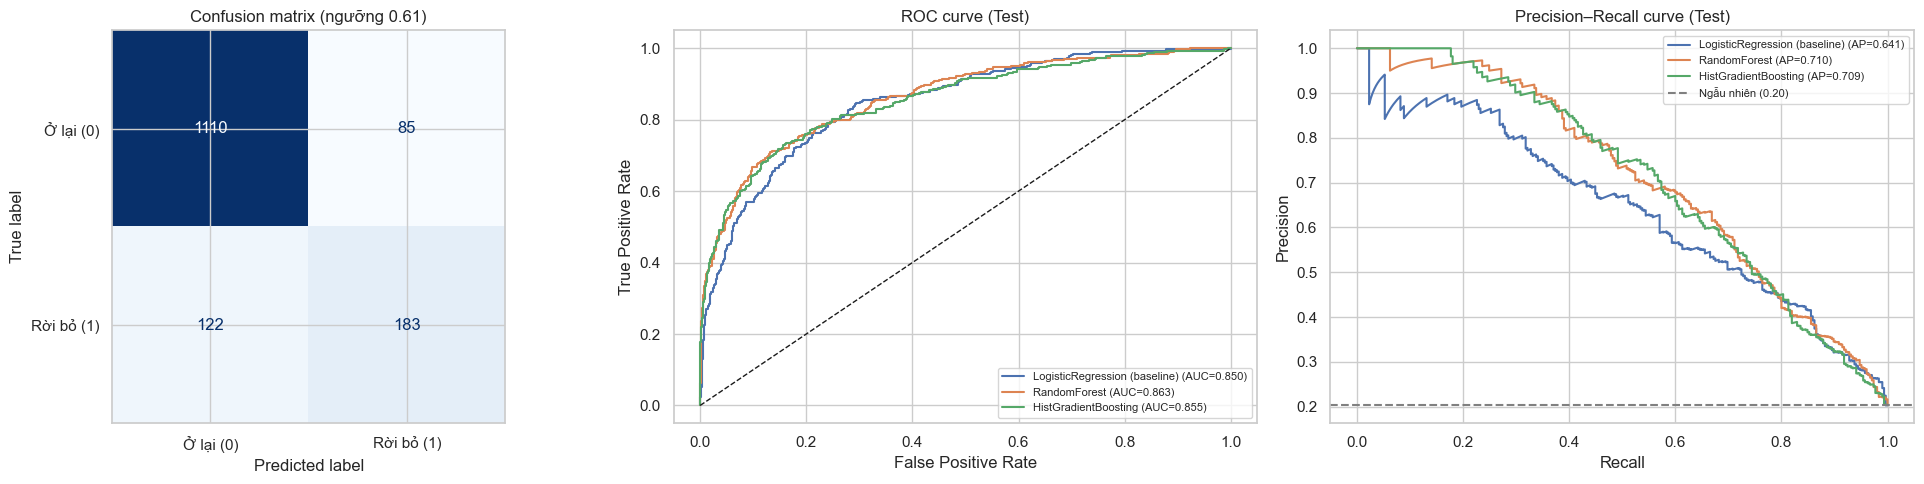

In [24]:
test_prob = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)
print(f'=== {best_name} (tuned), ngưỡng {best_threshold:.2f} — TẬP TEST ===')
print(classification_report(y_test, test_pred, target_names=list(CLASS_NAMES.values()), digits=3))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred), display_labels=list(CLASS_NAMES.values())).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion matrix (ngưỡng {best_threshold:.2f})')
for name, model in {'LogisticRegression (baseline)': models['LogisticRegression'], **tuned}.items():
    p = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, p):.3f})')
    axes[2].plot(rec, prec, label=f'{name} (AP={average_precision_score(y_test, p):.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set(title='ROC curve (Test)', xlabel='False Positive Rate', ylabel='True Positive Rate')
axes[2].axhline(y_test.mean(), ls='--', c='gray', label=f'Ngẫu nhiên ({y_test.mean():.2f})')
axes[2].set(title='Precision–Recall curve (Test)', xlabel='Recall', ylabel='Precision')
for ax in axes[1:]:
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 4.2. Từng bước cải tiến giúp bắt thêm được bao nhiêu khách hàng rời bỏ?

Đây là câu hỏi thứ hai đặt ra ở đầu bài. Để trả lời, nhóm so sánh bốn cấu hình trên **cùng một tập Test**,
mỗi lần chỉ thay đổi một thứ:

1. Baseline Logistic Regression, không xử lý mất cân bằng, ngưỡng 0,5.
2. Random Forest đã tinh chỉnh nhưng đặt `class_weight=None`, ngưỡng 0,5. So với bước 1, chỉ đổi thuật toán.
3. Thêm `class_weight='balanced'`, vẫn ngưỡng 0,5. So với bước 2, chỉ đổi cách xử lý mất cân bằng.
4. Thêm ngưỡng tối ưu chọn trên Validation. So với bước 3, chỉ đổi ngưỡng.

Cách tách từng bước như vậy cho biết mỗi kỹ thuật đóng góp bao nhiêu, thay vì chỉ so mô hình cuối với baseline.

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Bắt được (TP),Báo nhầm (FP)
Cấu hình,,,,,,,,
1. Baseline LogReg,0.845,0.739,0.370,0.493,0.850,0.641,113,40
2. RandomForest,0.863,0.800,0.433,0.562,0.863,0.713,132,33
3. + class_weight,0.821,0.545,0.715,0.618,0.863,0.710,218,182
4. + class_weight + ngưỡng 0.61,0.862,0.683,0.600,0.639,0.863,0.710,183,85


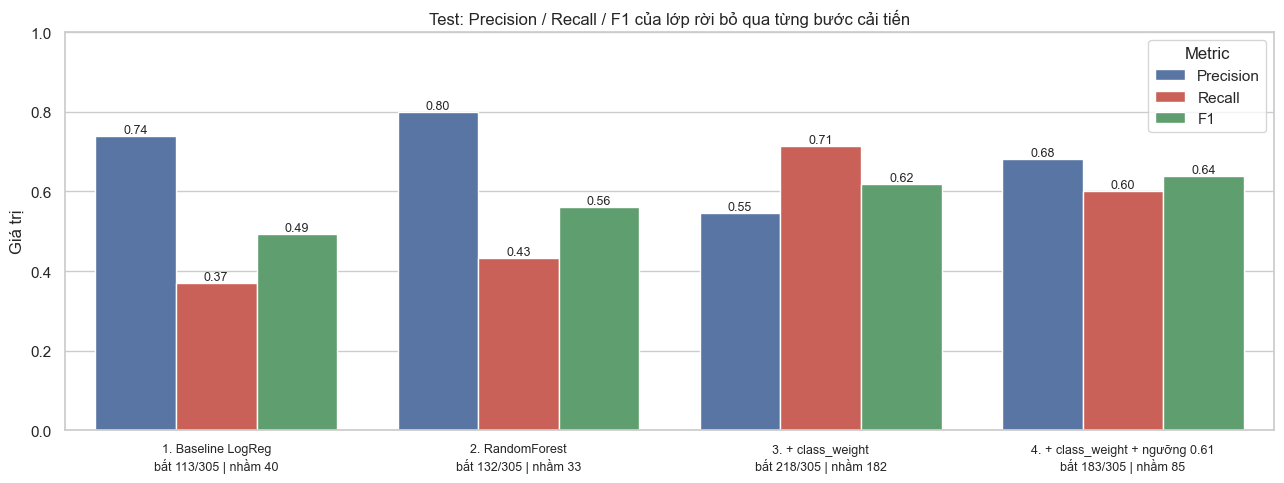

In [25]:
unweighted = clone(final_model).set_params(clf__class_weight=None).fit(X_train, y_train)
balanced = clone(final_model).set_params(clf__class_weight='balanced').fit(X_train, y_train)
balanced_val_prob = balanced.predict_proba(X_val)[:, 1]
balanced_threshold = max(THRESHOLDS, key=lambda t: f1_score(y_val, (balanced_val_prob >= t).astype(int)))

steps = [('1. Baseline LogReg', models['LogisticRegression'], 0.5),
         (f'2. {best_name}', unweighted, 0.5),
         ('3. + class_weight', balanced, 0.5),
         (f'4. + class_weight + ngưỡng {balanced_threshold:.2f}', balanced, balanced_threshold)]
step_rows = []
for label, model, thr in steps:
    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= thr).astype(int)
    step_rows.append({'Cấu hình': label, **evaluate(y_test, prob, thr),
                      'Bắt được (TP)': int(((pred == 1) & (y_test == 1)).sum()),
                      'Báo nhầm (FP)': int(((pred == 1) & (y_test == 0)).sum())})
steps_df = pd.DataFrame(step_rows).set_index('Cấu hình')
display(steps_df.style.format({c: '{:.3f}' for c in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']}))

fig, ax = plt.subplots(figsize=(13, 5))
long = steps_df[['Precision', 'Recall', 'F1']].reset_index().melt('Cấu hình', var_name='Metric', value_name='Giá trị')
sns.barplot(data=long, x='Cấu hình', y='Giá trị', hue='Metric', palette=['#4C72B0', '#DD5145', '#55A868'], ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=9)
n_pos = int(y_test.sum())
ax.set_xticks(range(len(steps_df)))
ax.set_xticklabels([f'{i}\nbắt {int(r["Bắt được (TP)"])}/{n_pos} | nhầm {int(r["Báo nhầm (FP)"])}'
                    for i, r in steps_df.iterrows()], fontsize=9)
ax.set(title='Test: Precision / Recall / F1 của lớp rời bỏ qua từng bước cải tiến', xlabel='', ylim=(0, 1))
plt.tight_layout(); plt.show()

Đọc hình theo từng bước, trên cùng tập Test có 305 khách hàng thực sự rời bỏ:

Baseline Logistic Regression chỉ bắt được 113 người, Recall 0,37 và F1 0,493.
Đổi sang Random Forest mà chưa xử lý mất cân bằng thì lên 132 người, F1 0,562.
Thêm `class_weight` là bước nhảy lớn nhất về Recall: bắt được 218 người tức 0,715, nhưng số lần báo nhầm
tăng vọt từ 33 lên 182. Nếu dừng ở đây thì gần một nửa danh sách cảnh báo là báo nhầm.
Dời ngưỡng lên 0,61 kéo lại cân bằng: bắt 183 người (Recall 0,60) và chỉ báo nhầm 85, đạt F1 cao nhất 0,639.

Tóm lại, mô hình cuối bắt thêm 70 khách hàng rời bỏ so với baseline, tăng 62%, và F1 tăng 0,146,
đổi lại có thêm 45 lần báo nhầm. Hai bước cải tiến có vai trò khác nhau: class weight kéo Recall lên,
còn chọn ngưỡng kéo Precision về.

Cần nói rõ là ngưỡng cuối cùng không nên do F1 quyết định mà do bài toán kinh doanh. Nếu chi phí gọi điện
chăm sóc rất rẻ so với giá trị một khách hàng mất đi thì nên giữ ngưỡng 0,5 để bắt 218 trên 305 người,
chấp nhận báo nhầm nhiều. Nhóm chọn tối ưu F1 vì không có dữ liệu chi phí thật.

### 4.3. Mức độ quan trọng của đặc trưng

Nhóm dùng permutation importance: xáo trộn ngẫu nhiên từng cột rồi đo mức giảm PR-AUC. Cách này áp dụng được
cho mọi mô hình và cho kết quả theo tên cột ban đầu, dễ giải thích hơn `feature_importances_` của cây
vốn trả về theo từng cột đã one-hot. Đo trên tập Test để phản ánh đúng dữ liệu mô hình chưa từng thấy.

,Mức giảm PR-AUC,std
NumOfProducts,0.284,0.020
Age,0.243,0.010
IsActiveMember,0.062,0.010
Geography,0.047,0.007
Balance,0.043,0.009
Gender,0.004,0.003
CreditScore,0.002,0.002
HasCrCard,0.001,0.001
Tenure,0.001,0.002
EstimatedSalary,-0.003,0.003


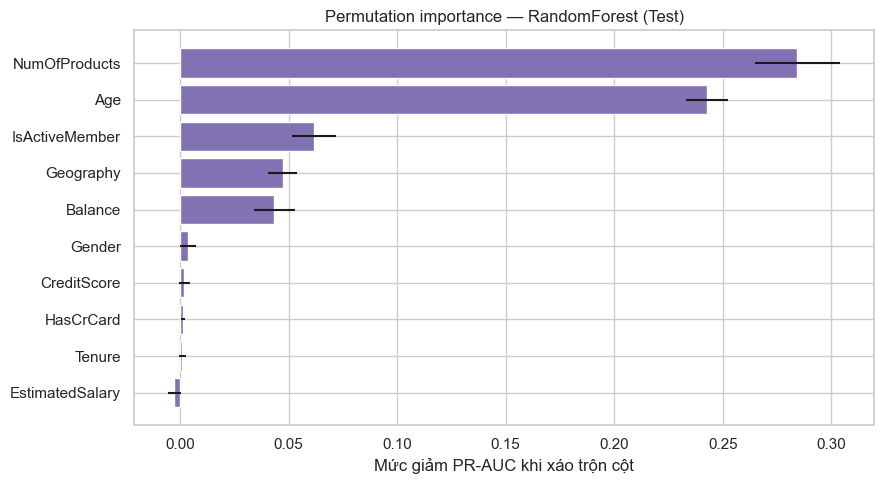

In [26]:
imp = permutation_importance(final_model, X_test, y_test, scoring='average_precision', n_repeats=10,
                             random_state=RANDOM_STATE, n_jobs=-1)
imp_df = pd.DataFrame({'Mức giảm PR-AUC': imp.importances_mean, 'std': imp.importances_std},
                      index=X_test.columns).sort_values('Mức giảm PR-AUC', ascending=False)
display(imp_df)

plt.figure(figsize=(9, 5))
plt.barh(imp_df.index[::-1], imp_df['Mức giảm PR-AUC'][::-1], xerr=imp_df['std'][::-1], color='#8172B3')
plt.title(f'Permutation importance — {best_name} (Test)'); plt.xlabel('Mức giảm PR-AUC khi xáo trộn cột')
plt.tight_layout(); plt.show()

Hai feature quan trọng vượt trội hẳn phần còn lại: xáo trộn NumOfProducts làm PR-AUC giảm 0,284 và
xáo trộn Age làm giảm 0,243. Tiếp theo là IsActiveMember (0,062), Geography (0,047) và Balance (0,043),
đã nhỏ hơn khoảng bốn lần. Gender, CreditScore, HasCrCard, Tenure và EstimatedSalary gần như không đóng góp gì,
đều dưới 0,004.

Kết quả này khớp với EDA ở mục 1.9, nơi NumOfProducts và Age cũng là hai yếu tố có chênh lệch tỉ lệ rời bỏ
lớn nhất. Việc EstimatedSalary vô dụng cũng không bất ngờ vì phân phối của nó gần như đều, giống dữ liệu
được sinh ngẫu nhiên.

### 4.4. Phân tích lỗi

Biết F1 bằng 0,639 vẫn chưa đủ để dùng mô hình. Câu hỏi thực tế hơn là mô hình sai ở đâu: nó bỏ sót
và báo nhầm ở những nhóm khách hàng nào, và liệu có thể sửa được không.

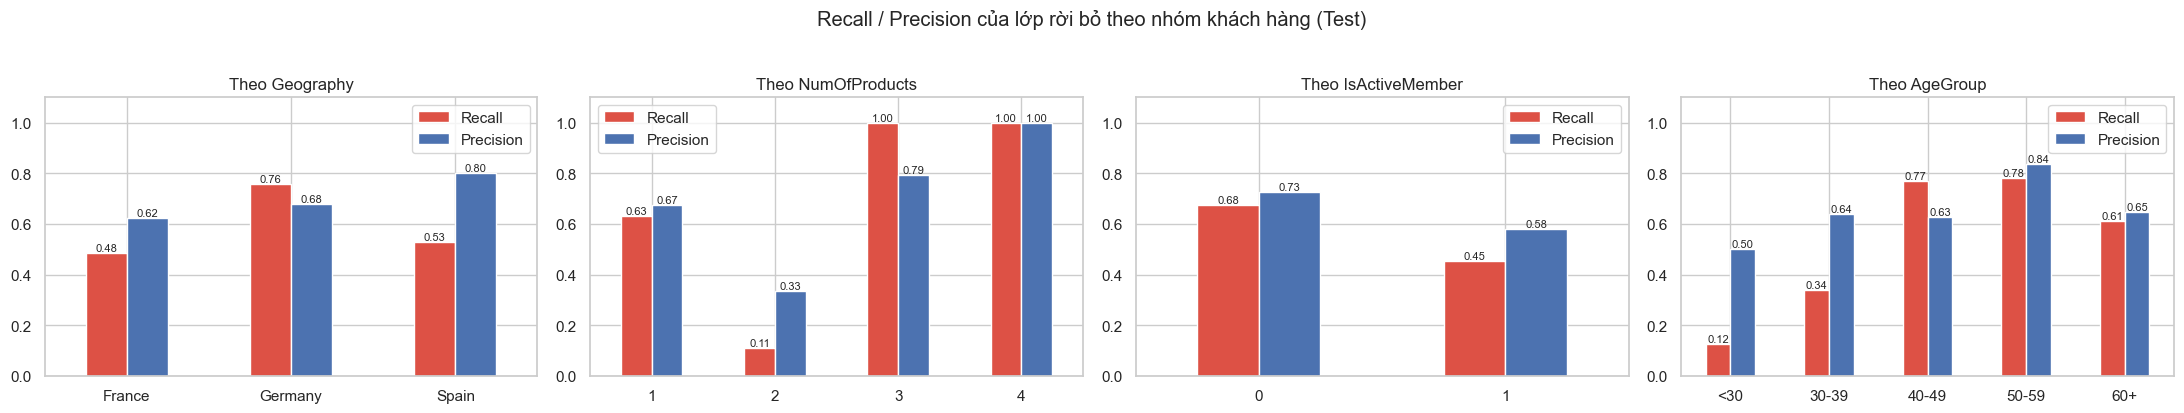

,Số KH,% rời bỏ thực tế,Recall,Precision
AgeGroup,,,,
<30,288,0.056,0.125,0.500
30-39,641,0.115,0.338,0.641
40-49,334,0.335,0.768,0.628
50-59,116,0.629,0.781,0.838
60+,60,0.300,0.611,0.647


False Negative: 122 | False Positive: 85


,Bỏ sót (FN),Bắt đúng (TP),Báo nhầm (FP)
Trung bình,,,
Age,41.179,48.746,45.893
Balance,"99,227.172","86,293.608","85,606.682"
CreditScore,638.554,645.915,647.434
NumOfProducts,1.336,1.514,1.306
IsActiveMember,0.467,0.257,0.400


Ví dụ khách hàng bị BỎ SÓT với xác suất thấp nhất:


,Age,Geography,Balance,NumOfProducts,IsActiveMember,prob
2141,18.000,France,0.000,2,1,0.037
9482,40.000,France,0.000,2,0,0.047
9539,29.000,France,"123,192.120",1,1,0.052
3317,71.000,France,0.000,2,1,0.056
1212,42.000,Spain,0.000,2,0,0.057


In [27]:
err = X_test.copy()
err['actual'], err['prob'], err['pred'] = y_test, test_prob, test_pred
err['AgeGroup'] = pd.cut(err['Age'], [0, 30, 40, 50, 60, 100], labels=['<30', '30-39', '40-49', '50-59', '60+'])

def segment_table(col):
    g = err.groupby(col, observed=True)
    return pd.DataFrame({'Số KH': g.size(), '% rời bỏ thực tế': g['actual'].mean(),
                         'Recall': g.apply(lambda d: recall_score(d.actual, d.pred, zero_division=0)),
                         'Precision': g.apply(lambda d: precision_score(d.actual, d.pred, zero_division=0))})

fig, axes = plt.subplots(1, 4, figsize=(22, 4))
for ax, col in zip(axes, ['Geography', 'NumOfProducts', 'IsActiveMember', 'AgeGroup']):
    t = segment_table(col)
    t[['Recall', 'Precision']].plot.bar(ax=ax, rot=0, color=['#DD5145', '#4C72B0'], ylim=(0, 1.1))
    for c in ax.containers:
        ax.bar_label(c, fmt='%.2f', fontsize=8)
    ax.set(title=f'Theo {col}', xlabel='')
plt.suptitle('Recall / Precision của lớp rời bỏ theo nhóm khách hàng (Test)', y=1.03)
plt.tight_layout(); plt.show()
display(segment_table('AgeGroup'))

fn, fp = err[(err.actual == 1) & (err.pred == 0)], err[(err.actual == 0) & (err.pred == 1)]
tp = err[(err.actual == 1) & (err.pred == 1)]
print(f'False Negative: {len(fn)} | False Positive: {len(fp)}')
cols = ['Age', 'Geography', 'Balance', 'NumOfProducts', 'IsActiveMember']
num_cmp = ['Age', 'Balance', 'CreditScore', 'NumOfProducts', 'IsActiveMember']
display(pd.DataFrame({'Bỏ sót (FN)': fn[num_cmp].mean(), 'Bắt đúng (TP)': tp[num_cmp].mean(),
                      'Báo nhầm (FP)': fp[num_cmp].mean()}).rename_axis('Trung bình'))
print('Ví dụ khách hàng bị BỎ SÓT với xác suất thấp nhất:')
display(fn.sort_values('prob')[cols + ['prob']].head(5))

Trên tập Test có 122 khách hàng rời bỏ bị bỏ sót và 85 lần báo nhầm.

Điểm yếu rõ nhất nằm ở khách hàng trẻ. Recall chỉ đạt 0,13 ở nhóm dưới 30 tuổi và 0,34 ở nhóm 30–39,
trong khi ở nhóm 40–59 đạt 0,77 đến 0,78. Lý do khá dễ hiểu: nhóm dưới 30 chỉ có 5,6% rời bỏ,
nên mô hình học được rằng đoán "ở lại" cho nhóm này gần như luôn đúng.

Chân dung những người bị bỏ sót cũng nhất quán với điều đó. Họ trẻ hơn (tuổi trung bình 41 so với 49 ở nhóm
bắt đúng) và hoạt động nhiều hơn (47% là thành viên tích cực so với 26%). Nói cách khác, họ trông giống
khách hàng trung thành. Năm ca bị bỏ sót với xác suất thấp nhất đều là khách hàng Pháp dùng 2 sản phẩm,
đúng nhóm có tỉ lệ rời bỏ thấp nhất trong EDA.

Hệ quả là với các feature hiện có, những khách hàng này gần như không thể phân biệt được. Không phải do
chọn sai thuật toán hay chưa tinh chỉnh đủ, mà do dữ liệu không chứa tín hiệu. Muốn bắt được họ thì cần
thêm dữ liệu hành vi: giao dịch gần đây, khiếu nại, tần suất đăng nhập, phản hồi với chương trình khuyến mãi.

### 4.5. Hàm suy luận

Hàm dưới đây nhận thông tin thô của một khách hàng, kể cả khi thiếu giá trị, rồi tự chạy toàn bộ pipeline
gồm tạo đặc trưng, điền thiếu, scale, encode và dự đoán, cuối cùng áp ngưỡng đã chọn.
Nhờ mọi bước tiền xử lý nằm trong pipeline nên người dùng không cần biết gì về chúng.
Khách hàng C trong ví dụ thiếu ba trường để kiểm tra xem hàm có chịu được dữ liệu khuyết hay không.

In [28]:
def predict_customer_churn(customer, model=final_model, threshold=best_threshold):
    x = pd.DataFrame([customer]).reindex(columns=X_train.columns)
    prob = float(model.predict_proba(x)[0, 1])
    return {'Xác suất rời bỏ': f'{prob:.1%}', 'Ngưỡng': threshold,
            'Kết luận': 'Nguy cơ rời bỏ, nên liên hệ giữ chân' if prob >= threshold else 'Ít nguy cơ'}


demo_customers = {
    'A. 52 tuổi, Đức, 1 sản phẩm, không hoạt động': dict(
        CreditScore=580, Geography='Germany', Gender='Female', Age=52, Tenure=2,
        Balance=125000.0, NumOfProducts=1, HasCrCard=1, IsActiveMember=0, EstimatedSalary=85000.0),
    'B. 30 tuổi, Pháp, 2 sản phẩm, hoạt động': dict(
        CreditScore=720, Geography='France', Gender='Male', Age=30, Tenure=6,
        Balance=0.0, NumOfProducts=2, HasCrCard=1, IsActiveMember=1, EstimatedSalary=60000.0),
    'C. thiếu Age, Balance, EstimatedSalary': dict(
        CreditScore=650, Geography='Spain', Gender='Female', Age=None, Tenure=4,
        Balance=None, NumOfProducts=3, HasCrCard=0, IsActiveMember=0, EstimatedSalary=None),
    'D. thiếu cả NumOfProducts và Geography': dict(
        CreditScore=700, Geography=None, Gender='Male', Age=45, Tenure=3,
        Balance=90000.0, NumOfProducts=None, HasCrCard=1, IsActiveMember=0, EstimatedSalary=70000.0),
}
display(pd.DataFrame({k: predict_customer_churn(v) for k, v in demo_customers.items()}).T)

,Xác suất rời bỏ,Ngưỡng,Kết luận
"A. 52 tuổi, Đức, 1 sản phẩm, không hoạt động",93.1%,0.610,"Nguy cơ rời bỏ, nên liên hệ giữ chân"
"B. 30 tuổi, Pháp, 2 sản phẩm, hoạt động",3.3%,0.610,Ít nguy cơ
"C. thiếu Age, Balance, EstimatedSalary",90.2%,0.610,"Nguy cơ rời bỏ, nên liên hệ giữ chân"
D. thiếu cả NumOfProducts và Geography,67.1%,0.610,"Nguy cơ rời bỏ, nên liên hệ giữ chân"


### 4.6. Kết luận, hạn chế và hướng phát triển

**Kết luận.** Mô hình cuối là Random Forest với `class_weight='balanced'` và ngưỡng 0,61.
Trên tập Test, mô hình đạt F1 0,639, Recall 0,60, Precision 0,68, ROC-AUC 0,863 và Accuracy 0,862.
So với baseline Logistic Regression (F1 0,493), mô hình bắt thêm được 70 trên 305 khách hàng rời bỏ.
F1 trên Validation (0,646) và trên Test (0,639) khá gần nhau, cho thấy việc chọn ngưỡng trên Validation
không bị overfit.

Về câu hỏi thứ nhất, yếu tố quyết định nhất là số sản phẩm và tuổi, sau đó mới tới mức độ hoạt động và quốc gia.
Nếu ngân hàng muốn dùng kết quả này, nhóm khách hàng nên ưu tiên chăm sóc là người 40–60 tuổi, ở Đức,
không hoạt động thường xuyên, đang dùng 1 sản phẩm hoặc từ 3 sản phẩm trở lên.

**Hạn chế.** C

Thứ nhất, missing values là do nhóm tự tạo theo cơ chế MCAR. Dữ liệu thiếu ngoài đời thường phụ thuộc vào
chính dữ liệu (MAR hoặc MNAR), ví dụ khách hàng thu nhập cao có xu hướng không khai lương. Những trường hợp đó
khó xử lý hơn nhiều và điền median sẽ làm lệch kết quả.

Thứ hai, EDA được thực hiện trên toàn bộ dữ liệu trước khi chia tập. Pipeline tiền xử lý thì hoàn toàn chỉ fit
trên Train nên không rò rỉ, nhưng các quyết định tạo đặc trưng như `IsZeroBalance` hay cách gộp `ProductsGroup`
có tham khảo gián tiếp thống kê của tập Test. Cách làm chặt chẽ hơn là chia tập trước rồi mới EDA trên Train.

Thứ ba, bộ dữ liệu chỉ là ảnh chụp tại một thời điểm, không có lịch sử hành vi theo thời gian,
nên mô hình bỏ sót hầu hết khách hàng trẻ như đã phân tích ở 4.4.

Thứ tư, ngưỡng được chọn theo F1, tức là mặc định coi một lần bỏ sót và một lần báo nhầm có chi phí ngang nhau.
Thực tế hiếm khi như vậy.

**Hướng phát triển.** Việc đáng làm nhất là thay tiêu chí chọn ngưỡng từ F1 sang chi phí kinh doanh thật,
dựa trên chi phí ưu đãi giữ chân so với doanh thu mất đi khi một khách hàng rời bỏ. Tiếp theo có thể thử
SMOTE hoặc các biến thể oversampling để so với class weight, và hiệu chỉnh xác suất (calibration) để dùng
đầu ra như điểm rủi ro thay vì chỉ nhãn 0/1. Về dữ liệu, bổ sung lịch sử giao dịch theo thời gian là cách
duy nhất để cải thiện nhóm khách hàng trẻ. Cuối cùng, nếu triển khai thật thì nên dùng SHAP để giải thích
từng dự đoán, vì nhân viên chăm sóc khách hàng cần biết lý do cụ thể trước khi gọi điện.